# Ray Data: write Parquet

Writes a dataset to a Parquet directory with SaveMode.OVERWRITE, so re-running the cell replaces the output.

**When to use it.** Materializing a processed dataset for later jobs or other tools.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

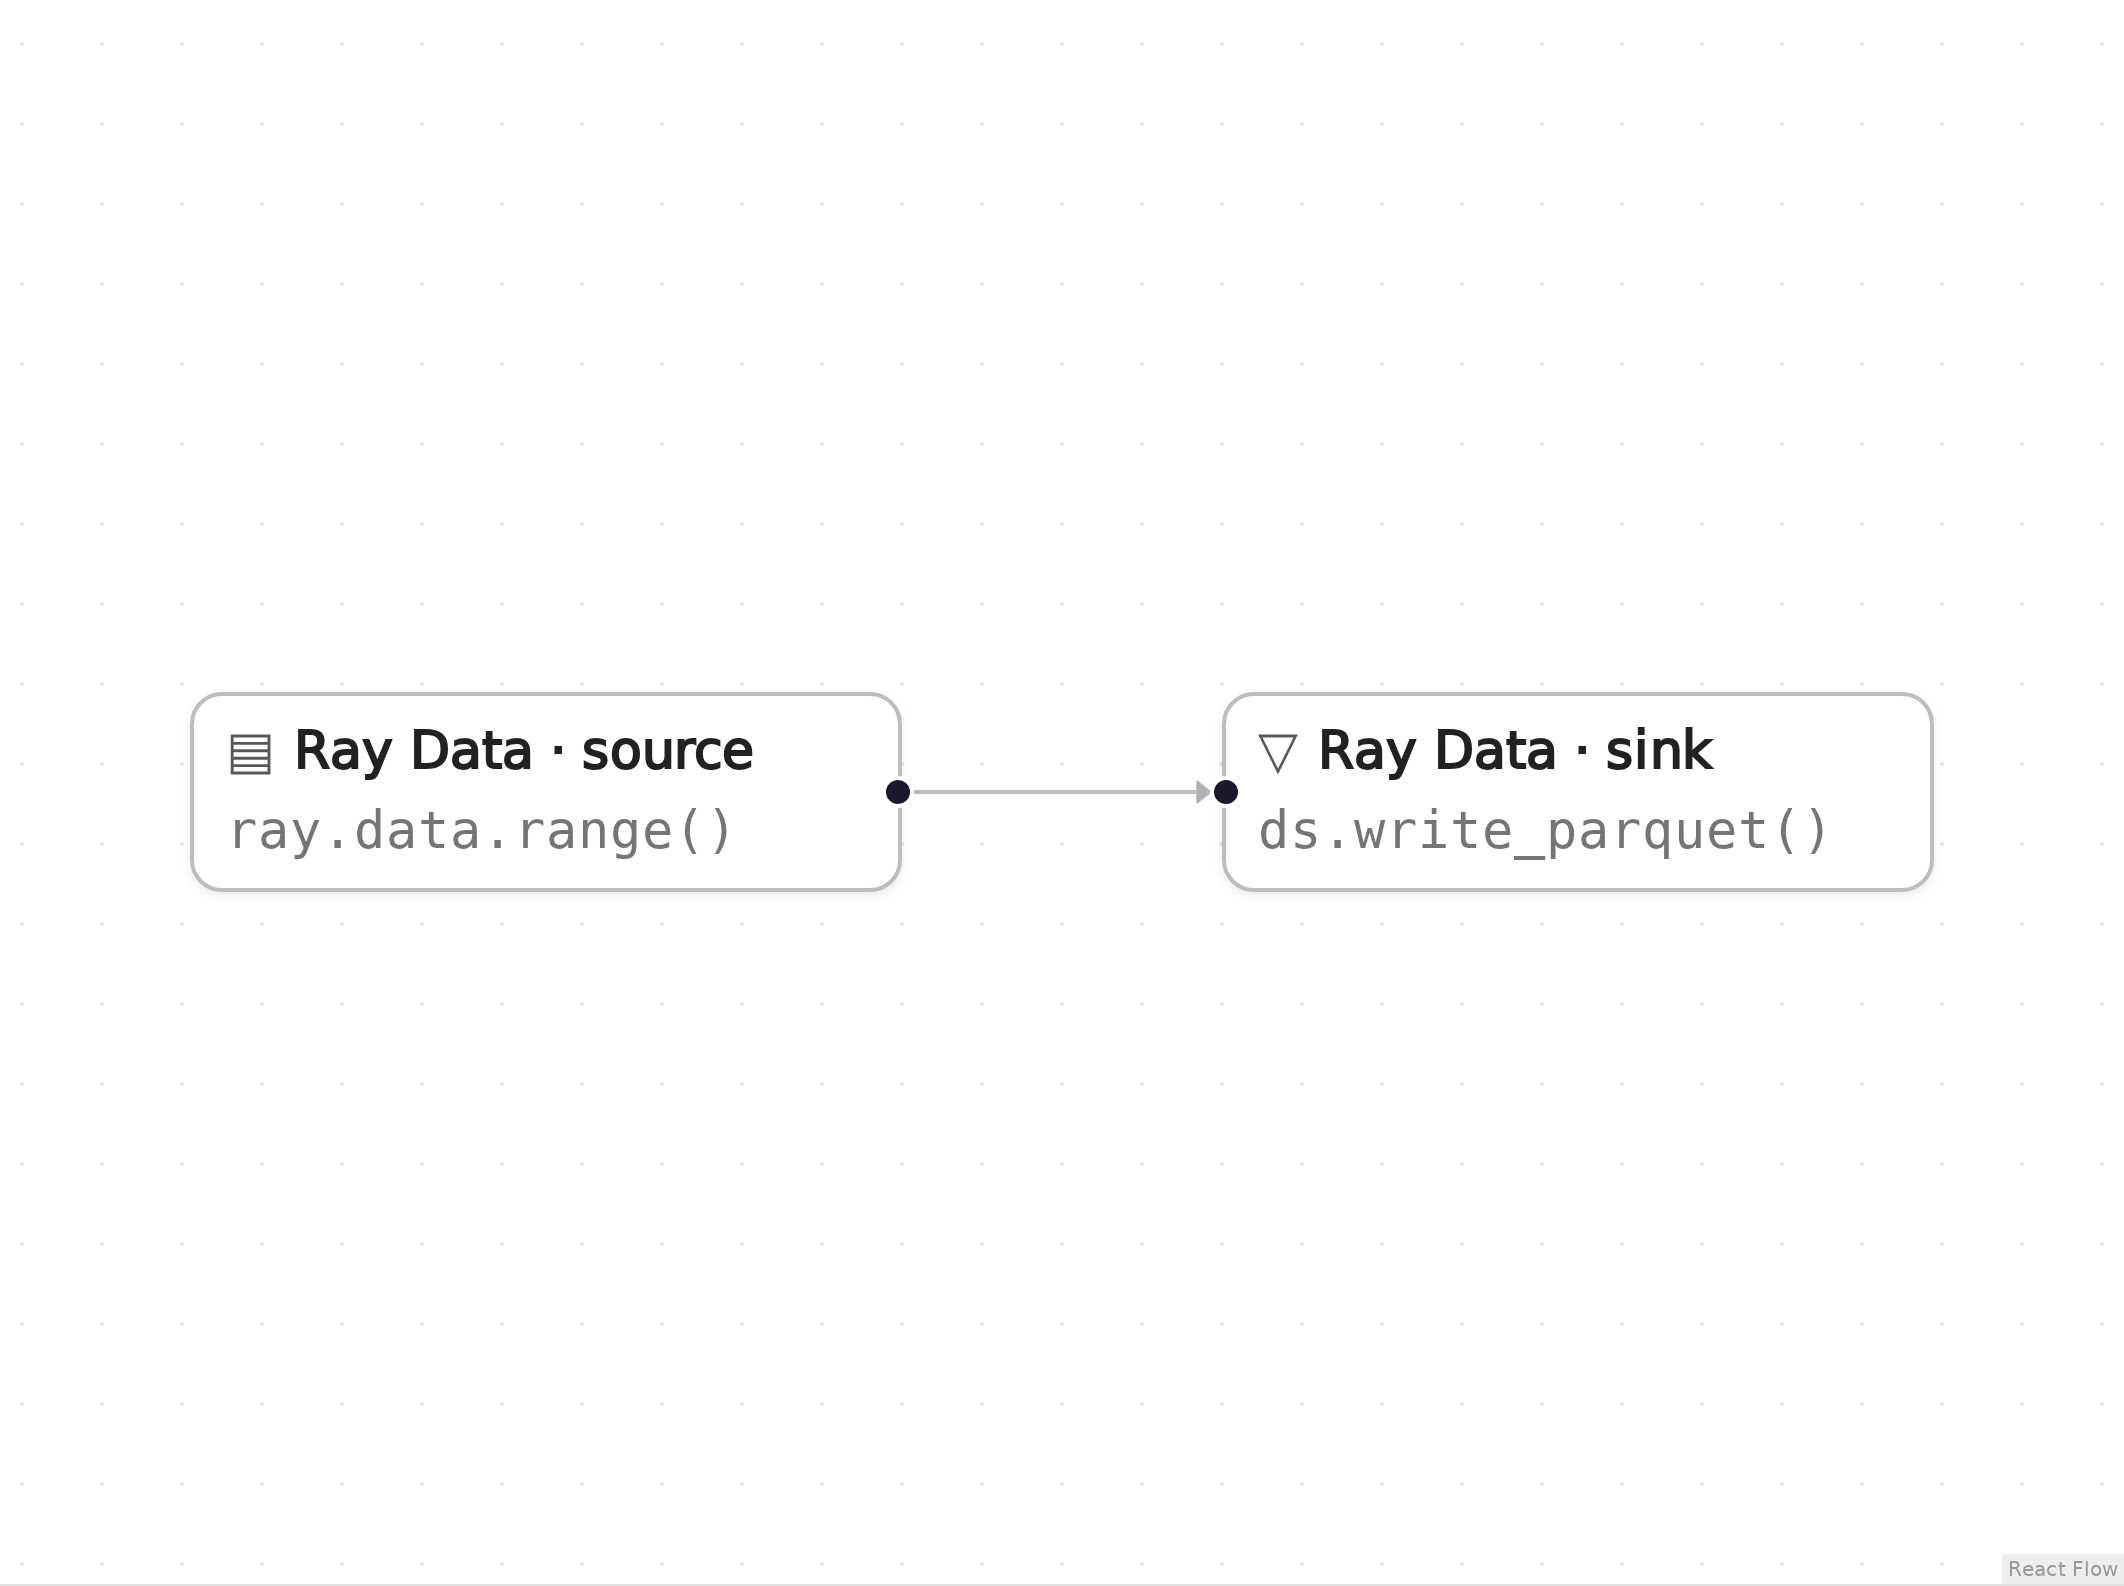

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

This pattern needs no user functions. Edit the output path in the write node.

## Generated code

This is the cell the visual builder generated from the graph above.

In [2]:
# Generated with Eugo's visual Ray builder

import ray
from ray.data import SaveMode

if not ray.is_initialized():
    ray.init()

ds = ray.data.range(100)
ds.write_parquet("/tmp/ray_patterns_out", mode=SaveMode.OVERWRITE)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [3]:
import shutil

_out = "/tmp/ray_patterns_out"
_cnt = ray.data.read_parquet(_out).count()
shutil.rmtree(_out, ignore_errors=True)
assert _cnt == 100, _cnt
print("rows written and read back =", _cnt)

rows written and read back = 100


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.data import SaveMode
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 9)

```python
ds = ray.data.range(100)
```

A 100-row dataset.

**Sink** (node `n2`, line 10)

```python
ds.write_parquet("/tmp/ray_patterns_out", mode=SaveMode.OVERWRITE)
```

write_parquet writes one file per block; mode=SaveMode.OVERWRITE replaces anything already at the path.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [4]:
ray.shutdown()